## Plotting Pressure against baryon density for symmetric nuclear matter at T = 10 MeV

The pressure is calculated at 3 different levels: first for an ideal proton, neutron and alpha gas, then for just nucleons and nucleon-nucleon interactions, and finally for the full virial expansion. This is done for T = 10 MeV and Y_p = 0.5, however the general code has been used so that Y_p can easily be modified.

In [1]:
# Imports

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq


In [2]:
# Define constants

T = 10.0 # Temp [MeV]
m_p = 938.272 # mass of proton [MeV/c^2]
lamda = 197.326 * (2 * np.pi/(m_p * T))**(1/2) # nucleon thermal wavelength [fm^-1] assuming m_p=m_n
lamda_alpha = lamda / 2 # alpha particle thermal wavelength [fm^-1]
E_alpha = 28.3 # alpha particle binding energy [MeV]
Y_p = 0.5 # proton fraction

# virial coefficients for T = 4 MeV
b_n = 0.311
b_pn = 1.91
b_nuc = 2.22
b_alpha_n = 2.95
b_alpha = 20.4

In [3]:

# Calculate fugacities

#-----------------------
# free n, p, alpha gas
#-----------------------

z_n_1 = np.linspace(1e-8, 0.32, 100) # range of neutron fugacities starting at small positive value

# ideal quadratic coefficients

a_1 = ((16*Y_p - 8)/(1 - Y_p)) * z_n_1**2 * np.exp(E_alpha/T)
b_1 = -1.0
c_1 = Y_p * z_n_1/(1 - Y_p)


z_p_1 = (2 * c_1) / (-b_1 + np.sqrt(b_1**2 - 4*a_1*c_1)) # proton fugacity calculated as roots of quadratic equation


z_alpha_1 = z_n_1**2 * z_p_1**2 * np.exp(E_alpha/T) # alpha particle fugacity

# free gas validity

valid_1 = ((z_n_1 < 0.32) & (z_p_1 < 0.32) & (z_alpha_1 < 0.17))

#---------------------------------------
# b_n, b_pn, b_nuc and zero alphas
#---------------------------------------

z_n_2 = np.linspace(1e-8, 0.51, 100) # range of neutron fugacities starting at small positive value

a_2 = ((16*Y_p - 8)/(1 - Y_p)) * z_n_2**2 * np.exp(E_alpha/T) - 2 * b_n
b_2 = (2 * Y_p)/(1 - Y_p) * z_n_2 * b_pn - 2 * z_n_2 * b_pn - 1
c_2 = (Y_p/(1 - Y_p)) * (z_n_2 + 2 * z_n_2**2 * b_n)

z_p_2 = (2 * c_2) / (-b_2 + np.sqrt(b_2**2 - 4*a_2*c_2)) # proton fugacity calculated as roots of quadratic equation

z_alpha_2 = 0.0  # alpha particle fugacity set to zero

# validity for no alphas

valid_2 = ((z_n_2 < 0.51) & (z_p_2 < 0.51))


#-------------------------------
# with all interactions
#-------------------------------

z_n_4 = np.linspace(1e-8, 0.21, 100) # range of neutron fugacities starting at small positive value

z_p_4 = []

for zn in z_n_4:
    a = ((32 * Y_p - 16)/(1 - Y_p)) * b_alpha * zn**4 * np.exp(2 * E_alpha/T)
    b = (32 * Y_p - 16)/(1 - Y_p) * b_alpha_n * zn**2 * np.exp(E_alpha/T) - 8 * b_alpha_n * zn**2 * np.exp(E_alpha/T)
    c = ((8 * Y_p)/(1 - Y_p)) * b_alpha_n * zn**3 * np.exp(E_alpha/T) + ((16 * Y_p - 8)/(1 - Y_p)) * (zn**2 * np.exp(E_alpha/T) + 2 * zn**3 * np.exp(E_alpha/T) * b_alpha_n) - 2 * b_n
    d = ((2 * Y_p)/(1 - Y_p)) * zn * b_pn - 1 - 2 * (zn * b_pn)
    e = (Y_p/(1 - Y_p)) * (zn + 2 * zn**2 * b_n)

    def g(z_p):
        return a * z_p**4 + b * z_p**3 + c * z_p**2 + d * z_p + e

    z_p = brentq(g, 0.0, 0.3)
    z_p_4.append(z_p)
z_p_4 = np.array(z_p_4)


z_alpha_4 = z_n_4**2 * z_p_4**2 * np.exp(E_alpha/T) # alpha particle fugacity

# validity for all interactions

valid_4 = ((z_n_4 < 0.21) & (z_p_4 < 0.21) & (z_alpha_4 < 0.04))

In [4]:
# Calculate number densities

#------------------------------
# free n, p, alpha gas
#------------------------------
n_n_1 = (2/lamda**3) * z_n_1 # neutron number density
n_p_1 = (2/lamda**3) * z_p_1 # proton number density
n_alpha_1 = (1/lamda_alpha**3) * z_alpha_1 # alpha particle number density
n_b_1 = (n_n_1 + n_p_1 + 4 * n_alpha_1) # baryon number density [fm^-3]

#------------------------------
# with b_n, b_pn, b_nuc and zero alphas
#------------------------------
n_n_2 = (2/lamda**3) * (z_n_2 + 2 * z_n_2**2 * b_n + 2 * z_n_2 * z_p_2 * b_pn)
n_p_2 = (2/lamda**3) * (z_p_2 + 2 * z_p_2**2 * b_n + 2 * z_n_2 * z_p_2 * b_pn)
n_alpha_2 = (1/lamda_alpha**3) * z_alpha_2
n_b_2 = (n_n_2 + n_p_2 + 4 * n_alpha_2)

#----------------------------
# with b_alpha
#----------------------------
n_n_4 = (2/lamda**3) * (z_n_4 + 2 * z_n_4**2 * b_n + 2 * z_n_4 * z_p_4 * b_pn + 8 * z_n_4 * z_alpha_4 * b_alpha_n)
n_p_4 = (2/lamda**3) * (z_p_4 + 2 * z_p_4**2 * b_n + 2 * z_n_4 * z_p_4 * b_pn + 8 * z_p_4 * z_alpha_4 * b_alpha_n)
n_alpha_4 = (1/lamda_alpha**3) * (z_alpha_4 + 2 * z_alpha_4 * (z_n_4 + z_p_4) * b_alpha_n + 2 * z_alpha_4**2 * b_alpha)
n_b_4 = (n_n_4 + n_p_4 + 4 * n_alpha_4)

In [5]:
# Calculate Presure

#-------------------
# Free n, p, alpha gas
#-------------------

P_1 = (2 * T / lamda**3) * (z_n_1 + z_p_1) + (T / lamda_alpha**3) * z_alpha_1 

#--------------------
# Virial, no alphas
#--------------------

P_2 = (2 * T / lamda**3) * (z_n_2 + z_p_2 + (z_n_2**2 + z_p_2**2) * b_n + 2 * z_n_2 * z_p_2 * b_pn)

#--------------------
# Full Virial
#--------------------

P_4 = (2 * T / lamda**3) * (z_n_4 + z_p_4 + (z_n_4**2 + z_p_4**2) * b_n + 2 * z_n_4 * z_p_4 * b_pn) + (T / lamda_alpha**3) * (z_alpha_4 + z_alpha_4**2 * b_alpha + 2 * z_alpha_4 * (z_n_4 + z_p_4) * b_alpha_n)


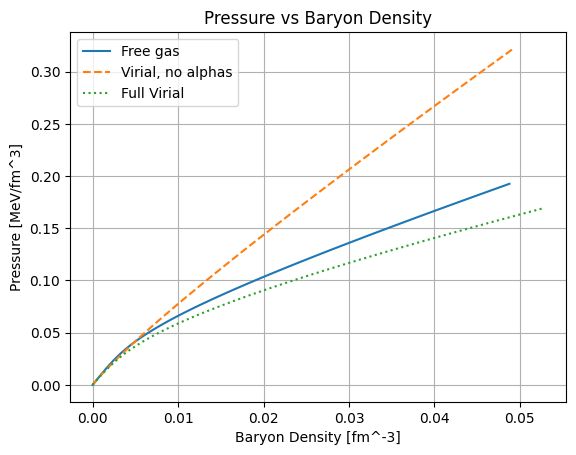

In [6]:
# Plot pressure vs baryon density

plt.plot(n_b_1[valid_1], P_1[valid_1], label='Free gas')
plt.plot(n_b_2[valid_2], P_2[valid_2], label='Virial, no alphas', linestyle='--')
plt.plot(n_b_4[valid_4], P_4[valid_4], label='Full Virial', linestyle=':')
plt.xlabel('Baryon Density [fm^-3]')
plt.ylabel('Pressure [MeV/fm^3]')
plt.title('Pressure vs Baryon Density')
plt.legend()
plt.grid()
